<a href="https://colab.research.google.com/github/Liliiyyy/Tugas-1_Estimasi/blob/main/Tugas1_AED_Lili_Harlia_251061003.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tugas 1 · Estimasi Rata-rata Tip dengan Distribusi Z, Jackknife, dan Bootstrap

Nama : Lili Harlia  
NIM : 251061003  
Materi : Pertemuan 9 – Estimasi Titik dan Interval  
Mata Kuliah : Analisis Eksplorasi Data

Pada tugas ini saya mengestimasi **rata-rata uang tip** (variabel `tip`) pada dataset *Tips*. Dari 244 data yang tersedia saya mengambil 100 sampel, lalu:

1. menghitung estimasi titik dan interval kepercayaan 95% memakai distribusi Z, dan
2. membandingkannya dengan hasil resampling jackknife (100 resample) dan bootstrap (1000 iterasi).

## Langkah 0 — Persiapan

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
ALPHA = 0.05      # tingkat kesalahan 5%
B     = 1000      # jumlah iterasi bootstrap

## Langkah 1 — Mengambil 100 sampel
Sampel diambil secara acak tanpa pengembalian dari 244 baris. `random_state` dikunci agar hasilnya bisa diulang.

In [2]:
tips_all = sns.load_dataset("tips")
contoh = tips_all["tip"].sample(n=100, random_state=2025).reset_index(drop=True)
contoh.to_csv("sampel_tip_100.csv", index=False)

x = contoh.to_numpy()
n = x.size
print(f"Data lengkap : {len(tips_all)} baris")
print(f"Sampel dipakai: {n} data")
contoh.describe().round(4).to_frame().T

Data lengkap : 244 baris
Sampel dipakai: 100 data


,count,mean,std,min,25%,50%,75%,max
tip,100.0,3.1837,1.5063,1.01,2.0,3.0,4.0,10.0


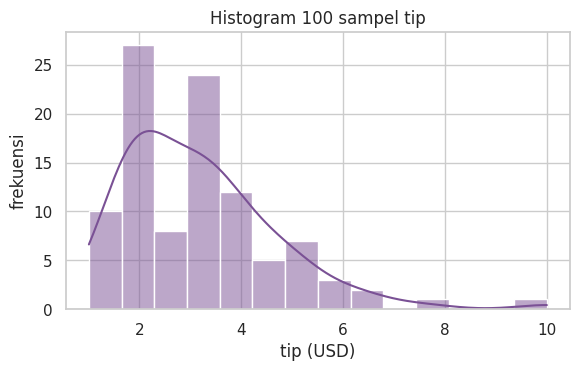

Shapiro-Wilk: W = 0.8914, p-value = 0.0000


In [3]:
plt.figure(figsize=(6.5, 3.6))
sns.histplot(x, kde=True, bins=14, color="#7a5195")
plt.title("Histogram 100 sampel tip"); plt.xlabel("tip (USD)"); plt.ylabel("frekuensi")
plt.show()

W, p = stats.shapiro(x)
print(f"Shapiro-Wilk: W = {W:.4f}, p-value = {p:.4f}")

**Interpretasi grafik 1:** histogram menunjukkan sebagian besar tip berkumpul di kisaran 2–4 USD, dengan ekor memanjang ke kanan (ada beberapa tip besar). Bentuk ini agak menceng ke kanan, jadi data tidak benar-benar normal (sejalan dengan uji Shapiro-Wilk, p < 0,05). Meskipun begitu, ukuran sampel saya $n = 100$ sudah besar, sehingga berdasarkan teorema limit pusat rata-rata sampel tetap mendekati normal dan distribusi Z boleh dipakai.

## Bagian A — Estimasi titik dan interval (distribusi Z)

Dari bagan keputusan di materi, rumus interval untuk rata-rata $\mu$ bergantung pada σ:

- σ diketahui → memakai $\sigma/\sqrt{n}$
- σ tidak diketahui dan $n \ge 30$ → memakai $s/\sqrt{n}$

Di sini σ populasi tidak diketahui dan $n=100$, jadi saya memakai $s$:

$$\bar X \;\pm\; Z_{\alpha/2}\,\frac{s}{\sqrt{n}}$$

Saya membuat fungsi kecil agar pemilihan rumusnya mengikuti bagan tersebut.

In [4]:
def interval_z(data, alpha=0.05, sigma=None):
    """Estimasi titik + interval (1-alpha) untuk rata-rata, sesuai bagan keputusan di materi."""
    data = np.asarray(data, dtype=float)
    m = data.size
    rata = data.mean()
    if sigma is None:                      # sigma tidak diketahui
        if m < 30:
            raise ValueError("n < 30 dan sigma tidak diketahui: gunakan distribusi t")
        sebaran = data.std(ddof=1)         # pakai s
    else:                                  # sigma diketahui
        sebaran = sigma
    z_kritis = stats.norm.ppf(1 - alpha/2)
    galat = sebaran / np.sqrt(m)
    return dict(rata=rata, sebaran=sebaran, z=z_kritis, galat=galat,
                bawah=rata - z_kritis*galat, atas=rata + z_kritis*galat)

zhasil = interval_z(x, ALPHA)
for k, v in zhasil.items():
    print(f"{k:8s}: {v:.4f}")

rata    : 3.1837
sebaran : 1.5063
z       : 1.9600
galat   : 0.1506
bawah   : 2.8885
atas    : 3.4789


Estimasi titik          : 3.1837
Interval kepercayaan 95%: 2.8885  s/d  3.4789
(pembanding) rata-rata 244 data = 2.9983 -> masuk interval


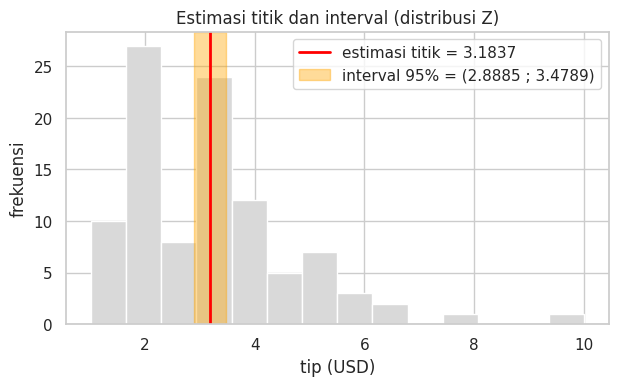

In [5]:
mu_pop = tips_all["tip"].mean()
print(f"Estimasi titik          : {zhasil['rata']:.4f}")
print(f"Interval kepercayaan 95%: {zhasil['bawah']:.4f}  s/d  {zhasil['atas']:.4f}")
print(f"(pembanding) rata-rata 244 data = {mu_pop:.4f} -> "
      f"{'masuk' if zhasil['bawah'] <= mu_pop <= zhasil['atas'] else 'tidak masuk'} interval")

plt.figure(figsize=(7, 3.8))
plt.hist(x, bins=14, color="#d9d9d9", edgecolor="white")
plt.axvline(zhasil["rata"], color="red", lw=2, label=f"estimasi titik = {zhasil['rata']:.4f}")
plt.axvspan(zhasil["bawah"], zhasil["atas"], color="orange", alpha=0.4,
            label=f"interval 95% = ({zhasil['bawah']:.4f} ; {zhasil['atas']:.4f})")
plt.title("Estimasi titik dan interval (distribusi Z)")
plt.xlabel("tip (USD)"); plt.ylabel("frekuensi")
plt.legend(); plt.show()

In [6]:
from IPython.display import Markdown
Markdown(f'''
**Interpretasi grafik 2:** batang abu-abu adalah sebaran 100 tip, garis merah
adalah estimasi titik (**{zhasil['rata']:.4f}**), dan area oranye adalah
interval kepercayaan 95% (**{zhasil['bawah']:.4f} – {zhasil['atas']:.4f}**).
Dengan tingkat kesalahan 5%, saya yakin 95% bahwa rata-rata tip yang sebenarnya
berada di dalam area oranye. Area ini jauh lebih sempit daripada sebaran datanya
karena yang diestimasi adalah *rata-rata* (galatnya s/√n), bukan satu nilai tip.
Rata-rata dari seluruh 244 data ({mu_pop:.4f}) juga berada di dalam interval
ini.
''')


**Interpretasi grafik 2:** batang abu-abu adalah sebaran 100 tip, garis merah
adalah estimasi titik (**3.1837**), dan area oranye adalah
interval kepercayaan 95% (**2.8885 – 3.4789**).
Dengan tingkat kesalahan 5%, saya yakin 95% bahwa rata-rata tip yang sebenarnya
berada di dalam area oranye. Area ini jauh lebih sempit daripada sebaran datanya
karena yang diestimasi adalah *rata-rata* (galatnya s/√n), bukan satu nilai tip.
Rata-rata dari seluruh 244 data (2.9983) juga berada di dalam interval
ini.


## Bagian B — Resampling

### B.1 Jackknife (leave-one-out, 100 resample)

Setiap kali satu pengamatan dibuang, rata-rata dihitung dari $n-1 = 99$ data sisanya. Notasi di materi:

- $\hat\theta$ : rata-rata seluruh data; $\hat\theta_{(i)}$ : rata-rata tanpa data ke-$i$
- $\bar\theta_{(\cdot)} = \frac1n\sum_i \hat\theta_{(i)}$
- Bias: $(n-1)(\bar\theta_{(\cdot)}-\hat\theta)$, estimator terkoreksi: $n\hat\theta-(n-1)\bar\theta_{(\cdot)}$
- $SE_J=\sqrt{\frac{n-1}{n}\sum_i(\hat\theta_{(i)}-\bar\theta_{(\cdot)})^2}$

Banyak resample jackknife : 100
Rata-rata hasil jackknife : 3.1837
Bias                      : 0.000000
Estimator terkoreksi bias : 3.1837
SE jackknife              : 0.1506


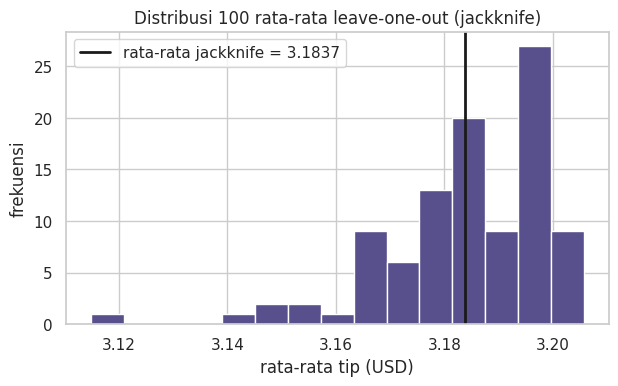

In [7]:
def jackknife_mean(data):
    data = np.asarray(data, dtype=float)
    m = data.size
    # baris ke-i = data tanpa elemen ke-i
    tanpa_i = [data[np.arange(m) != i] for i in range(m)]
    theta_i = np.array([baris.mean() for baris in tanpa_i])

    theta_hat = data.mean()
    theta_pt  = theta_i.mean()
    bias      = (m - 1) * (theta_pt - theta_hat)
    return {
        "theta_i": theta_i,
        "theta_hat": theta_hat,
        "rata_jk": theta_pt,
        "bias": bias,
        "terkoreksi": m * theta_hat - (m - 1) * theta_pt,
        "se": np.sqrt((m - 1) / m * np.sum((theta_i - theta_pt) ** 2)),
    }

jk = jackknife_mean(x)
print(f"Banyak resample jackknife : {jk['theta_i'].size}")
print(f"Rata-rata hasil jackknife : {jk['rata_jk']:.4f}")
print(f"Bias                      : {jk['bias']:.6f}")
print(f"Estimator terkoreksi bias : {jk['terkoreksi']:.4f}")
print(f"SE jackknife              : {jk['se']:.4f}")

plt.figure(figsize=(7, 3.8))
plt.hist(jk["theta_i"], bins=15, color="#58508d", edgecolor="white")
plt.axvline(jk["rata_jk"], color="k", lw=2, label=f"rata-rata jackknife = {jk['rata_jk']:.4f}")
plt.title("Distribusi 100 rata-rata leave-one-out (jackknife)")
plt.xlabel("rata-rata tip (USD)"); plt.ylabel("frekuensi")
plt.legend(); plt.show()

In [8]:
Markdown(f'''
**Interpretasi grafik 3:** setiap batang adalah rata-rata dari 99 data (satu
pengamatan dibuang). Seluruh 100 nilainya sangat berdekatan, yaitu antara
**{jk['theta_i'].min():.4f}** dan **{jk['theta_i'].max():.4f}**, dan berpusat di
rata-rata jackknife **{jk['rata_jk']:.4f}** (garis hitam), sama dengan rata-rata
sampel. Artinya membuang satu pengamatan hampir tidak mengubah rata-rata,
sehingga estimasinya stabil. Nilai paling kecil muncul saat pengamatan dengan
tip terbesar ({x.max():.2f}) dibuang, sedangkan nilai paling besar muncul saat
tip terkecil ({x.min():.2f}) dibuang.
''')


**Interpretasi grafik 3:** setiap batang adalah rata-rata dari 99 data (satu
pengamatan dibuang). Seluruh 100 nilainya sangat berdekatan, yaitu antara
**3.1148** dan **3.2057**, dan berpusat di
rata-rata jackknife **3.1837** (garis hitam), sama dengan rata-rata
sampel. Artinya membuang satu pengamatan hampir tidak mengubah rata-rata,
sehingga estimasinya stabil. Nilai paling kecil muncul saat pengamatan dengan
tip terbesar (10.00) dibuang, sedangkan nilai paling besar muncul saat
tip terkecil (1.01) dibuang.


### B.2 Bootstrap (1000 iterasi)

Dari 100 data asli, saya mengambil 100 data **dengan pengembalian**, menghitung rata-ratanya, dan mengulang sebanyak $B=1000$ kali. Rata-rata dari 1000 replikasi ini adalah $\bar\theta^{*}$.

In [9]:
gen = np.random.default_rng(777)
# tiap baris = satu sampel bootstrap (indeks dengan pengembalian)
indeks = gen.integers(0, n, size=(B, n))
theta_b = x[indeks].mean(axis=1)             # 1000 rata-rata bootstrap

rata_boot = theta_b.mean()
se_boot   = theta_b.std(ddof=1)
ci_boot   = np.percentile(theta_b, [2.5, 97.5])

print(f"Banyak iterasi bootstrap  : {theta_b.size}")
print(f"Rata-rata hasil bootstrap : {rata_boot:.4f}")
print(f"Bias bootstrap            : {rata_boot - zhasil['rata']:.4f}")
print(f"SE bootstrap              : {se_boot:.4f}")
print(f"CI 95% (persentil)        : {ci_boot[0]:.4f}  s/d  {ci_boot[1]:.4f}")

Banyak iterasi bootstrap  : 1000
Rata-rata hasil bootstrap : 3.1820
Bias bootstrap            : -0.0017
SE bootstrap              : 0.1522
CI 95% (persentil)        : 2.8843  s/d  3.4917


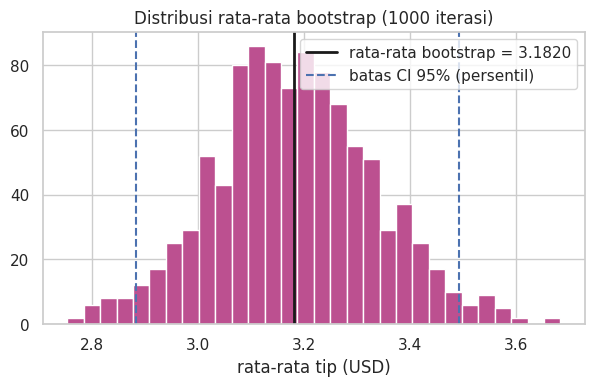

In [10]:
plt.figure(figsize=(7, 3.8))
plt.hist(theta_b, bins=30, color="#bc5090", edgecolor="white")
plt.axvline(rata_boot, color="k", lw=2, label=f"rata-rata bootstrap = {rata_boot:.4f}")
plt.axvline(ci_boot[0], color="b", ls="--", label="batas CI 95% (persentil)")
plt.axvline(ci_boot[1], color="b", ls="--")
plt.title("Distribusi rata-rata bootstrap (1000 iterasi)")
plt.xlabel("rata-rata tip (USD)")
plt.legend(); plt.show()

In [11]:
Markdown(f'''
**Interpretasi grafik 4:** histogram menunjukkan 1000 rata-rata hasil
pengambilan sampel ulang. Bentuknya mendekati lonceng dan simetris di sekitar
rata-rata bootstrap (**{rata_boot:.4f}**, garis hitam), yang hampir sama dengan
rata-rata sampel (**{zhasil['rata']:.4f}**). Garis putus-putus biru menandai 95%
nilai di tengah, yaitu **{ci_boot[0]:.4f} – {ci_boot[1]:.4f}**, dan nilainya
mirip dengan interval Z. Bentuk lonceng ini mendukung bahwa rata-rata sampel
berdistribusi mendekati normal, sehingga pemakaian distribusi Z pada bagian A
masuk akal.
''')


**Interpretasi grafik 4:** histogram menunjukkan 1000 rata-rata hasil
pengambilan sampel ulang. Bentuknya mendekati lonceng dan simetris di sekitar
rata-rata bootstrap (**3.1820**, garis hitam), yang hampir sama dengan
rata-rata sampel (**3.1837**). Garis putus-putus biru menandai 95%
nilai di tengah, yaitu **2.8843 – 3.4917**, dan nilainya
mirip dengan interval Z. Bentuk lonceng ini mendukung bahwa rata-rata sampel
berdistribusi mendekati normal, sehingga pemakaian distribusi Z pada bagian A
masuk akal.


## Bagian C — Perbandingan tiga pendekatan

In [12]:
perbandingan = pd.DataFrame(
    {
        "Z (rumus)":          [zhasil["rata"], zhasil["galat"], zhasil["bawah"], zhasil["atas"]],
        "Jackknife (n=100)":  [jk["rata_jk"],  jk["se"],        np.nan,          np.nan],
        "Bootstrap (B=1000)": [rata_boot,      se_boot,         ci_boot[0],      ci_boot[1]],
    },
    index=["rata-rata", "standard error", "batas bawah 95%", "batas atas 95%"],
).round(4)
perbandingan

,Z (rumus),Jackknife (n=100),Bootstrap (B=1000)
rata-rata,3.1837,3.1837,3.1820
standard error,0.1506,0.1506,0.1522
batas bawah 95%,2.8885,NaN,2.8843
batas atas 95%,3.4789,NaN,3.4917


## Kesimpulan

In [13]:
from IPython.display import Markdown
Markdown(f'''
1. Dari 100 sampel `tip`, **estimasi titik** rata-rata tip adalah
   **{zhasil['rata']:.4f} USD**, dan **interval kepercayaan 95%** (Z, α = 5%)
   adalah **{zhasil['bawah']:.4f} – {zhasil['atas']:.4f} USD**.
2. Rata-rata dari **100 resample jackknife** adalah **{jk['rata_jk']:.4f}**.
   Nilainya sama dengan rata-rata sampel (bias ≈ {jk['bias']:.4f}) karena
   rata-rata adalah estimator yang tak bias.
3. Rata-rata dari **1000 iterasi bootstrap** adalah **{rata_boot:.4f}**, sangat
   dekat dengan rata-rata sampel. Selisih kecilnya berasal dari pengambilan
   sampel acak.
4. Standard error ketiganya hampir sama ({zhasil['galat']:.4f}, {jk['se']:.4f},
   dan {se_boot:.4f}), jadi hasil rumus Z dan hasil resampling saling
   menguatkan.
''')


1. Dari 100 sampel `tip`, **estimasi titik** rata-rata tip adalah
   **3.1837 USD**, dan **interval kepercayaan 95%** (Z, α = 5%)
   adalah **2.8885 – 3.4789 USD**.
2. Rata-rata dari **100 resample jackknife** adalah **3.1837**.
   Nilainya sama dengan rata-rata sampel (bias ≈ 0.0000) karena
   rata-rata adalah estimator yang tak bias.
3. Rata-rata dari **1000 iterasi bootstrap** adalah **3.1820**, sangat
   dekat dengan rata-rata sampel. Selisih kecilnya berasal dari pengambilan
   sampel acak.
4. Standard error ketiganya hampir sama (0.1506, 0.1506,
   dan 0.1522), jadi hasil rumus Z dan hasil resampling saling
   menguatkan.
